# Navier-Stokes surrogate — reconstructing a flow, and where it fails

Our second PDE benchmark is the **lid-driven cavity**: incompressible flow in a box whose top lid
slides at $U=1$, driving a primary vortex. We solve it once with the Chapter-1 projection solver,
then train a black-box surrogate $(x,y)\mapsto(u,v)$ from velocity samples in the **lower part of
the cavity only** --- as if our sensors could not reach the top. We then ask it to fill in the
region it never saw, right under the moving lid. Inside the sampled region the reconstruction is
excellent (interpolation); in the unseen boundary layer it is badly wrong (extrapolation), because
nothing told the surrogate a thin high-shear layer lives there. Partial observations plus a black
box is a classic digital-twin trap.

**The ground truth.** The benchmark integrates the incompressible Navier--Stokes equations
$$ \frac{\partial\boldsymbol u}{\partial t} + (\boldsymbol u\cdot\nabla)\boldsymbol u
   = -\frac1\rho\nabla p + \nu\,\nabla^2\boldsymbol u, \qquad \nabla\cdot\boldsymbol u = 0, $$
with a Chorin projection method (predictor $\to$ pressure-Poisson $\to$ divergence-free corrector)
on a $61\times61$ grid, density $\rho=1$ and kinematic viscosity $\nu = UL/\mathrm{Re}$.
**BC:** no-slip ($\boldsymbol u=\boldsymbol 0$) on the left, right and bottom walls, and a moving
top lid $u=U=1,\ v=0$. **IC:** fluid at rest, $\boldsymbol u=\boldsymbol 0$. **Parameters:**
$\mathrm{Re}=400$, $L=1$. **Spatial train/test split:** "sensors" observe only $y\le0.65$; a random
15 % of those points is held out for the **interpolation** test, and the entire unobserved band
$y>0.65$ — which contains the thin, fast lid boundary layer — is the **extrapolation** test.

cavity solved at Re=400 on 61x61;  max speed = 1.000


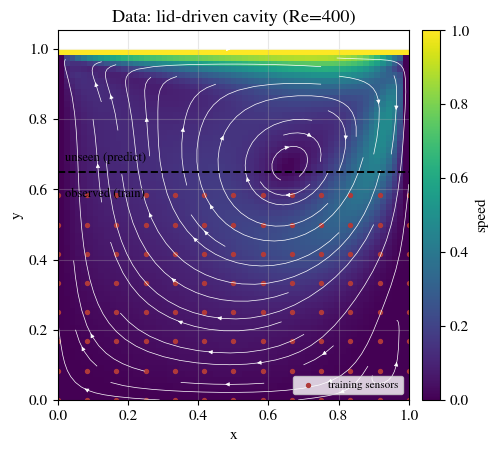

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils.pinn_core import MLP
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.benchmarks.navier_stokes import lid_driven_cavity
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

# --- ground truth: one lid-driven-cavity solve (Chapter-1 projection method) ---
NX = 61; RE = 400.0; L = 1.0
dx = L / (NX - 1); dt = 0.15 * dx
x = np.linspace(0, L, NX); Xg, Yg = np.meshgrid(x, x, indexing='ij')
_, _, u, v, p = lid_driven_cavity(nx=NX, ny=NX, nt=2500, nit=80, Re=RE, dt=dt)
speed = np.sqrt(u**2 + v**2)
print(f'cavity solved at Re={RE:.0f} on {NX}x{NX};  max speed = {speed.max():.3f}')

# sensors only below y = YCUT; the lid boundary layer above is unobserved
YCUT = 0.65

def plot_ddm_ns_data():
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    im = ax.imshow(speed.T, origin='lower', extent=[0, 1, 0, 1], cmap='viridis',
                   vmin=0, vmax=1, aspect='equal')
    ax.streamplot(x, x, u.T, v.T, color='white', density=0.7, linewidth=0.5, arrowsize=0.6)
    # scatter a sample of the training sensors (below the cut)
    si, sj = np.meshgrid(np.arange(0, NX, 5), np.arange(0, NX, 5), indexing='ij')
    keep = x[sj] <= YCUT
    ax.scatter(x[si][keep], x[sj][keep], s=8, color='C3', label='training sensors')
    ax.axhline(YCUT, ls='--', color=fg(), lw=1.4)
    ax.text(0.02, YCUT + 0.03, 'unseen (predict)', color=fg(), fontsize=9)
    ax.text(0.02, YCUT - 0.07, 'observed (train)', color=fg(), fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label='speed')
    ax.set(xlabel='x', ylabel='y', title=f'Data: lid-driven cavity (Re={RE:.0f})')
    ax.legend(loc='lower right', fontsize=8)

save_dual(plot_ddm_ns_data, 'ddm_ns_data', FIG); plt.show()

The solve reports a **maximum speed of 1.000**, reached only at the lid itself — confirming the
moving-wall BC drives the flow. The figure shows why the spatial split is dangerous: white
streamlines trace the single primary vortex (its centre sits high and to the right, near
$(0.6,\,0.75)$), colour is speed, and the dashed line at $y=0.65$ separates the red training
sensors below from the withheld band above. Almost all the fast fluid — the bright layer skimming
the top lid and the jet descending the right wall — lives **above** the cut, in the region the
surrogate never samples. Nothing in the training data below the line hints that $|\boldsymbol u|$
jumps to $1$ at the top.

## Train below the line, predict above it

The split is **in space**: train on velocity samples with $y\le 0.65$, hold out a random 15 % of
them as an interpolation test, and treat the whole unobserved top band ($y>0.65$) as the
extrapolation test — points outside the training footprint entirely. The surrogate
`MLP([2, 64, 64, 64, 2])` maps $(x,y)\to(\hat u,\hat v)$; inputs and the two velocity targets are
standardized on the training set, and we minimize the mean-squared velocity error
$$ \mathcal L(\theta)=\frac1N\sum_i\big\lVert(\hat u_i,\hat v_i)-(u_i,v_i)\big\rVert^2 $$
with 5000 Adam steps (`lr=2e-3`). We then score per-point velocity RMSE separately on the held-out
interpolation points (below the cut) and the extrapolation band (above it), and map the error over
the whole cavity.

final train loss 2.71e-05
RMSE  interpolation (held-out, below cut) = 0.0005
RMSE  extrapolation (unseen lid band)     = 0.2876
extrapolation error is 530x the interpolation error


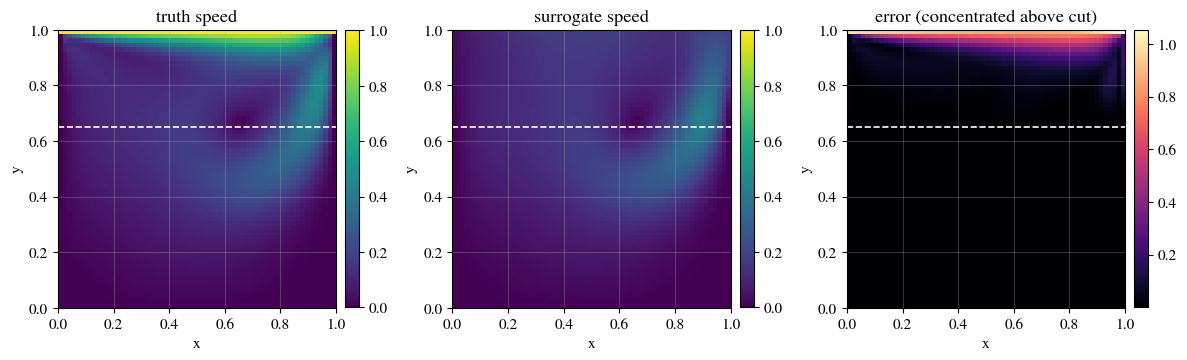

In [2]:
xs, ys = Xg.ravel(), Yg.ravel()
U, Vv = u.ravel(), v.ravel()
seen = ys <= YCUT; unseen = ys > YCUT
rng = np.random.default_rng(1)
idx = np.where(seen)[0]
hold = rng.choice(idx, size=int(0.15 * len(idx)), replace=False)   # interpolation test
train_mask = seen.copy(); train_mask[hold] = False
interp_mask = np.zeros_like(seen); interp_mask[hold] = True

X = np.c_[xs, ys]; Yt_all = np.c_[U, Vv]
Xm, Xs = X[train_mask].mean(0), X[train_mask].std(0)
Ym, Ys = Yt_all[train_mask].mean(0), Yt_all[train_mask].std(0)
Xt = torch.tensor((X[train_mask] - Xm) / Xs)
Yt = torch.tensor((Yt_all[train_mask] - Ym) / Ys)

torch.manual_seed(0); net = MLP([2, 64, 64, 64, 2])
opt = torch.optim.Adam(net.parameters(), lr=2e-3)
for ep in range(5000):
    opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
print('final train loss %.2e' % float(loss.detach()))

with torch.no_grad():
    pred = net(torch.tensor((X - Xm) / Xs)).numpy() * Ys + Ym
err = np.sqrt(((pred - Yt_all)**2).sum(1))          # per-point velocity error
e_interp = float(np.sqrt(np.mean(err[interp_mask]**2)))
e_extrap = float(np.sqrt(np.mean(err[unseen]**2)))
print(f'RMSE  interpolation (held-out, below cut) = {e_interp:.4f}')
print(f'RMSE  extrapolation (unseen lid band)     = {e_extrap:.4f}')
print(f'extrapolation error is {e_extrap/e_interp:.0f}x the interpolation error')

spd_pred = np.sqrt(pred[:, 0]**2 + pred[:, 1]**2).reshape(NX, NX)
err2d = err.reshape(NX, NX)

def plot_ddm_ns_cliff():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
    for a, F, ttl in [(ax[0], speed, 'truth speed'),
                       (ax[1], spd_pred, 'surrogate speed')]:
        im = a.imshow(F.T, origin='lower', extent=[0, 1, 0, 1], cmap='viridis',
                      vmin=0, vmax=1.0, aspect='equal')
        a.axhline(YCUT, ls='--', color='white', lw=1.2)
        a.set(title=ttl, xlabel='x', ylabel='y')
        fig.colorbar(im, ax=a, fraction=0.046, pad=0.03)
    im = ax[2].imshow(err2d.T, origin='lower', extent=[0, 1, 0, 1], cmap='magma', aspect='equal')
    ax[2].axhline(YCUT, ls='--', color='white', lw=1.2)
    ax[2].set(title='error (concentrated above cut)', xlabel='x', ylabel='y')
    fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.03)
    plt.tight_layout()

save_dual(plot_ddm_ns_cliff, 'ddm_ns_cliff', FIG); plt.show()
assert e_extrap > 20 * e_interp      # reconstruction fails in the unobserved boundary layer

The gap here is even more brutal than the heat case: interpolation RMSE **0.0005** below the cut
versus extrapolation RMSE **0.2876** in the unseen band — a **$530\times$** jump (the `assert`
demands only $>20\times$), despite a tiny final train loss of $2.71\times10^{-5}$. The three panels
tell the story: *truth* (left) shows the bright lid layer feeding the vortex; the *surrogate*
(middle) reproduces the flow perfectly below the dashed cut but flattens to near-zero above it,
completely missing the yellow lid boundary layer; the *error* map (right) is black everywhere below
the cut and lights up only in the thin band along the very top, exactly where no sensor reached. The
black box smoothly extends the interior flow upward, with no notion that a high-shear layer is
waiting there and no signal that it is extrapolating.

**Lesson.** Where it has data the surrogate reconstructs the flow almost exactly, and it is far
cheaper to evaluate than the Navier-Stokes solver. But it has no momentum equation, so in the
unobserved band it simply extends the smooth interior flow and completely misses the thin lid shear
layer --- the error there is hundreds of times larger, with no warning. A physics-informed model
would enforce the Navier-Stokes residual *everywhere*, including where there are no sensors, and so
recover the boundary layer it never measured. Keep the physics, learn only what is uncertain.
**This is the case for HAM.**